In [1]:
import sys

print(sys.executable)
print(sys.version)

c:\MLProjects\NetworkML\.venv\Scripts\python.exe
3.11.5 (tags/v3.11.5:cce6ba9, Aug 24 2023, 14:38:34) [MSC v.1936 64 bit (AMD64)]


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

Matplotlib is building the font cache; this may take a moment.


All libraries imported successfully!


In [3]:
from pathlib import Path

DATA_DIR = Path("../data/raw")

csv_files = list(DATA_DIR.glob("*.csv"))

print(f"Number of CSV files: {len(csv_files)}")

for file in csv_files:
    print(file.name)

Number of CSV files: 8
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Friday-WorkingHours-Morning.pcap_ISCX.csv
Monday-WorkingHours.pcap_ISCX.csv
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Tuesday-WorkingHours.pcap_ISCX.csv
Wednesday-workingHours.pcap_ISCX.csv


In [4]:
for file in csv_files:
    size_mb = file.stat().st_size / (1024 ** 2)
    print(f"{file.name}: {size_mb:.2f} MB")

Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv: 73.55 MB
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv: 73.34 MB
Friday-WorkingHours-Morning.pcap_ISCX.csv: 55.62 MB
Monday-WorkingHours.pcap_ISCX.csv: 168.73 MB
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv: 79.25 MB
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv: 49.61 MB
Tuesday-WorkingHours.pcap_ISCX.csv: 128.82 MB
Wednesday-workingHours.pcap_ISCX.csv: 214.74 MB


In [5]:
import pandas as pd

sample_file = DATA_DIR / "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv"

sample_df = pd.read_csv(sample_file, nrows=5)

print("Shape:", sample_df.shape)
print("\nColumns:")
print(sample_df.columns.tolist())

Shape: (5, 79)

Columns:
[' Destination Port', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', 'Bwd Packet Length Max', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length', ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s', ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Variance', 'FIN Flag Count', ' SYN Flag Count', ' RST Flag Count', ' PSH Flag Count', ' ACK

In [6]:
sample_df.head()
sample_df.info()
sample_df[" Label"].value_counts()

<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 79 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0    Destination Port             5 non-null      int64  
 1    Flow Duration                5 non-null      int64  
 2    Total Fwd Packets            5 non-null      int64  
 3    Total Backward Packets       5 non-null      int64  
 4   Total Length of Fwd Packets   5 non-null      int64  
 5    Total Length of Bwd Packets  5 non-null      int64  
 6    Fwd Packet Length Max        5 non-null      int64  
 7    Fwd Packet Length Min        5 non-null      int64  
 8    Fwd Packet Length Mean       5 non-null      int64  
 9    Fwd Packet Length Std        5 non-null      int64  
 10  Bwd Packet Length Max         5 non-null      int64  
 11   Bwd Packet Length Min        5 non-null      int64  
 12   Bwd Packet Length Mean       5 non-null      int64  
 13   Bwd Packet Length S

 Label
BENIGN    5
Name: count, dtype: int64

In [7]:
from collections import Counter

label_counts = Counter()

for file in csv_files:
    labels = pd.read_csv(
        file,
        usecols=[" Label"]
    )

    counts = labels[" Label"].value_counts()

    print(f"\n{file.name}")
    print(counts)

    label_counts.update(labels[" Label"])


Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
 Label
DDoS      128027
BENIGN     97718
Name: count, dtype: int64

Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
 Label
PortScan    158930
BENIGN      127537
Name: count, dtype: int64

Friday-WorkingHours-Morning.pcap_ISCX.csv
 Label
BENIGN    189067
Bot         1966
Name: count, dtype: int64

Monday-WorkingHours.pcap_ISCX.csv
 Label
BENIGN    529918
Name: count, dtype: int64

Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
 Label
BENIGN          288566
Infiltration        36
Name: count, dtype: int64

Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
 Label
BENIGN                        168186
Web Attack � Brute Force        1507
Web Attack � XSS                 652
Web Attack � Sql Injection        21
Name: count, dtype: int64

Tuesday-WorkingHours.pcap_ISCX.csv
 Label
BENIGN         432074
FTP-Patator      7938
SSH-Patator      5897
Name: count, dtype: int64

Wednesday-workingHours.pcap_ISCX.csv
 Label
BENIGN

In [8]:
print("\n========== OVERALL LABEL DISTRIBUTION ==========")

for label, count in label_counts.most_common():
    print(f"{label}: {count:,}")


========== OVERALL LABEL DISTRIBUTION ==========
BENIGN: 2,273,097
DoS Hulk: 231,073
PortScan: 158,930
DDoS: 128,027
DoS GoldenEye: 10,293
FTP-Patator: 7,938
SSH-Patator: 5,897
DoS slowloris: 5,796
DoS Slowhttptest: 5,499
Bot: 1,966
Web Attack � Brute Force: 1,507
Web Attack � XSS: 652
Infiltration: 36
Web Attack � Sql Injection: 21
Heartbleed: 11


In [9]:
# Load a small sample again
sample_df = pd.read_csv(
    DATA_DIR / "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv",
    nrows=1000
)

# Remove leading/trailing spaces from column names
sample_df.columns = sample_df.columns.str.strip()

print(sample_df.columns.tolist())

['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'CWE Flag Count', 'ECE Flag Count

In [10]:
print("Missing values:")
print(sample_df.isna().sum().sum())

print("\nInfinite values:")
print(np.isinf(sample_df.select_dtypes(include=np.number)).sum().sum())

Missing values:
0

Infinite values:
2


In [11]:
print("Duplicate rows:", sample_df.duplicated().sum())

Duplicate rows: 0


In [12]:
inf_counts = np.isinf(
    sample_df.select_dtypes(include=np.number)
).sum()

print(inf_counts[inf_counts > 0])

Flow Bytes/s      1
Flow Packets/s    1
dtype: int64


In [13]:
sample_df.loc[
    np.isinf(sample_df.select_dtypes(include=np.number)).any(axis=1)
]

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
65,55043,0,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [14]:
sample_df["Target"] = (
    sample_df["Label"] != "BENIGN"
).astype(int)

print(sample_df["Target"].value_counts())

Target
0    1000
Name: count, dtype: int64


In [15]:
comparison = sample_df.groupby("Target")[
    [
        "Flow Duration",
        "Total Fwd Packets",
        "Total Backward Packets",
        "Total Length of Fwd Packets",
        "Total Length of Bwd Packets",
        "Flow Packets/s",
        "Flow Bytes/s"
    ]
].median()

comparison

,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Flow Packets/s,Flow Bytes/s
Target,,,,,,,
0,77439.0,2.0,2.0,94.0,215.5,187.328517,13367.4712


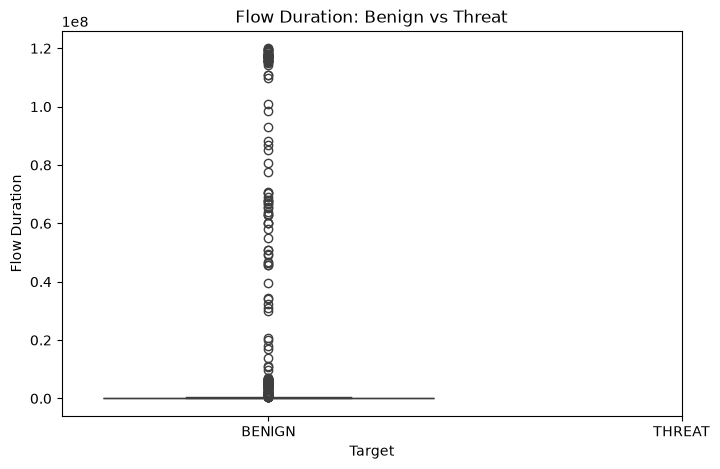

In [16]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=sample_df,
    x="Target",
    y="Flow Duration"
)

plt.xticks([0, 1], ["BENIGN", "THREAT"])
plt.title("Flow Duration: Benign vs Threat")
plt.show()

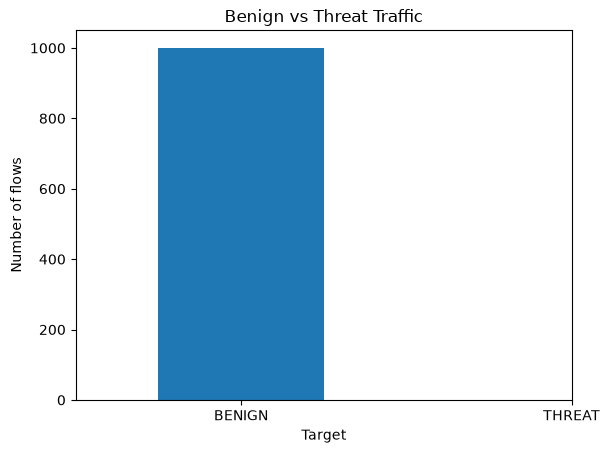

In [17]:
sample_df["Target"].value_counts().plot(
    kind="bar"
)

plt.xticks(
    [0, 1],
    ["BENIGN", "THREAT"],
    rotation=0
)

plt.ylabel("Number of flows")
plt.title("Benign vs Threat Traffic")
plt.show()

In [4]:
import pandas as pd
import numpy as np
from pathlib import Path

DATA_PATH = Path("../data/raw")

csv_files = list(DATA_PATH.glob("*.csv"))

print(f"Found {len(csv_files)} CSV files:")
for file in csv_files:
    print("-", file.name)

Found 8 CSV files:
- Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
- Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
- Friday-WorkingHours-Morning.pcap_ISCX.csv
- Monday-WorkingHours.pcap_ISCX.csv
- Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
- Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
- Tuesday-WorkingHours.pcap_ISCX.csv
- Wednesday-workingHours.pcap_ISCX.csv


In [5]:
# The four classes for Version 1 of our model
selected_classes = [
    "BENIGN",
    "DDoS",
    "PortScan",
    "DoS Hulk"
]

# How many rows we want from each class
SAMPLES_PER_CLASS = 20_000

selected_data = []

for file in csv_files:
    print(f"Reading: {file.name}")

    # Read the file
    df = pd.read_csv(file, low_memory=False)

    # Clean column names
    df.columns = df.columns.str.strip()

    # Keep only our selected classes
    filtered = df[df["Label"].isin(selected_classes)]

    # Sample each class present in this file
    for label in selected_classes:
        class_data = filtered[filtered["Label"] == label]

        if len(class_data) > 0:
            sample_size = min(
                len(class_data),
                SAMPLES_PER_CLASS
            )

            sample = class_data.sample(
                n=sample_size,
                random_state=42
            )

            selected_data.append(sample)

            print(f"  {label}: {sample_size} rows")

# Combine everything
model_df = pd.concat(selected_data, ignore_index=True)

print("\nFinal dataset shape:", model_df.shape)

print("\nClass distribution:")
print(model_df["Label"].value_counts())

Reading: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
  BENIGN: 20000 rows
  DDoS: 20000 rows
Reading: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
  BENIGN: 20000 rows
  PortScan: 20000 rows
Reading: Friday-WorkingHours-Morning.pcap_ISCX.csv
  BENIGN: 20000 rows
Reading: Monday-WorkingHours.pcap_ISCX.csv
  BENIGN: 20000 rows
Reading: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
  BENIGN: 20000 rows
Reading: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
  BENIGN: 20000 rows
Reading: Tuesday-WorkingHours.pcap_ISCX.csv
  BENIGN: 20000 rows
Reading: Wednesday-workingHours.pcap_ISCX.csv
  BENIGN: 20000 rows
  DoS Hulk: 20000 rows

Final dataset shape: (220000, 79)

Class distribution:
Label
BENIGN      160000
DDoS         20000
PortScan     20000
DoS Hulk     20000
Name: count, dtype: int64


In [6]:
# Balance the dataset:
# Keep exactly 20,000 samples from each class

balanced_data = []

for label in selected_classes:
    class_data = model_df[model_df["Label"] == label]
    
    balanced_sample = class_data.sample(
        n=20_000,
        random_state=42
    )
    
    balanced_data.append(balanced_sample)

# Combine all balanced classes
model_df = pd.concat(balanced_data, ignore_index=True)

# Shuffle the final dataset
model_df = model_df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("Final balanced dataset shape:", model_df.shape)

print("\nClass distribution:")
print(model_df["Label"].value_counts())

Final balanced dataset shape: (80000, 79)

Class distribution:
Label
PortScan    20000
DoS Hulk    20000
BENIGN      20000
DDoS        20000
Name: count, dtype: int64


In [7]:
# Replace infinity values with NaN
model_df = model_df.replace([np.inf, -np.inf], np.nan)

# Check missing values after replacement
print("Missing values:", model_df.isnull().sum().sum())

# Remove rows containing missing values
model_df = model_df.dropna()

print("Dataset shape after cleaning:", model_df.shape)

# Separate features and target
X = model_df.drop("Label", axis=1)
y = model_df["Label"]

print("\nX shape:", X.shape)
print("y shape:", y.shape)

print("\nClasses:")
print(y.value_counts())

Missing values: 206
Dataset shape after cleaning: (79897, 79)

X shape: (79897, 78)
y shape: (79897,)

Classes:
Label
DDoS        19999
PortScan    19989
BENIGN      19988
DoS Hulk    19921
Name: count, dtype: int64


In [6]:
# Split the dataset into training and testing sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

NameError: name 'X' is not defined

In [9]:
# Train a Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier

# Create the model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
print("Training the model...")

model.fit(X_train, y_train)

print("Model training complete! 🎉")

Training the model...
Model training complete! 🎉


In [7]:
# Evaluate the model
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Make predictions on data the model has NEVER seen
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy:.4f}")
print(f"Model Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

NameError: name 'model' is not defined

<Figure size 800x600 with 0 Axes>

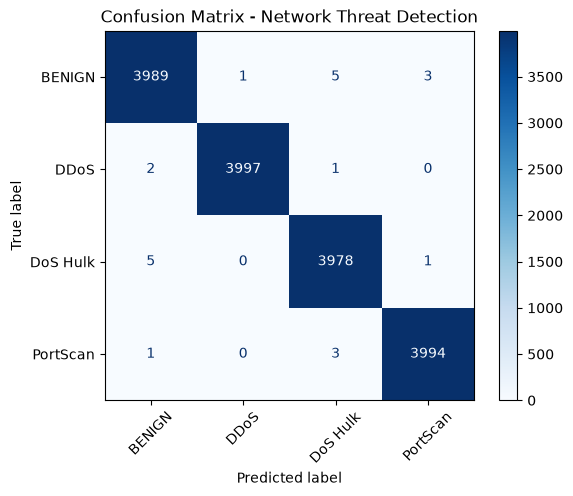

In [11]:
# Display the confusion matrix
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

plt.figure(figsize=(8, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Confusion Matrix - Network Threat Detection")

plt.show()

In [12]:
import joblib
from pathlib import Path

# Create the models folder if it doesn't exist
MODELS_PATH = Path("../models")
MODELS_PATH.mkdir(exist_ok=True)

# Save the trained model
model_path = MODELS_PATH / "threat_detection_model.joblib"

joblib.dump(model, model_path)

print(f"Model saved successfully at: {model_path}")

Model saved successfully at: ..\models\threat_detection_model.joblib


In [13]:
print("model" in globals())

True


In [14]:
import joblib
from pathlib import Path

# Define where our trained models will be stored
MODELS_PATH = Path("../models")

# Create the folder if it doesn't already exist
MODELS_PATH.mkdir(exist_ok=True)

# Define the complete file path
model_path = MODELS_PATH / "threat_detection_model.joblib"

# Save the trained model
joblib.dump(model, model_path)

print(f"Model saved successfully at: {model_path}")

Model saved successfully at: ..\models\threat_detection_model.joblib


In [15]:
import joblib

loaded_model = joblib.load("../models/threat_detection_model.joblib")

print("Model loaded successfully!")
print(type(loaded_model))

Model loaded successfully!
<class 'sklearn.ensemble._forest.RandomForestClassifier'>


In [5]:
sample = X_test.iloc[0]

print(sample)

NameError: name 'X_test' is not defined

In [17]:
sample_dict = sample.to_dict()

print(sample_dict)

{'Destination Port': 8300.0, 'Flow Duration': 29.0, 'Total Fwd Packets': 1.0, 'Total Backward Packets': 1.0, 'Total Length of Fwd Packets': 0.0, 'Total Length of Bwd Packets': 6.0, 'Fwd Packet Length Max': 0.0, 'Fwd Packet Length Min': 0.0, 'Fwd Packet Length Mean': 0.0, 'Fwd Packet Length Std': 0.0, 'Bwd Packet Length Max': 6.0, 'Bwd Packet Length Min': 6.0, 'Bwd Packet Length Mean': 6.0, 'Bwd Packet Length Std': 0.0, 'Flow Bytes/s': 206896.5517, 'Flow Packets/s': 68965.51724, 'Flow IAT Mean': 29.0, 'Flow IAT Std': 0.0, 'Flow IAT Max': 29.0, 'Flow IAT Min': 29.0, 'Fwd IAT Total': 0.0, 'Fwd IAT Mean': 0.0, 'Fwd IAT Std': 0.0, 'Fwd IAT Max': 0.0, 'Fwd IAT Min': 0.0, 'Bwd IAT Total': 0.0, 'Bwd IAT Mean': 0.0, 'Bwd IAT Std': 0.0, 'Bwd IAT Max': 0.0, 'Bwd IAT Min': 0.0, 'Fwd PSH Flags': 0.0, 'Bwd PSH Flags': 0.0, 'Fwd URG Flags': 0.0, 'Bwd URG Flags': 0.0, 'Fwd Header Length': 40.0, 'Bwd Header Length': 20.0, 'Fwd Packets/s': 34482.75862, 'Bwd Packets/s': 34482.75862, 'Min Packet Length': 

In [18]:
request_data = {
    "features": sample_dict
}

print(request_data)

{'features': {'Destination Port': 8300.0, 'Flow Duration': 29.0, 'Total Fwd Packets': 1.0, 'Total Backward Packets': 1.0, 'Total Length of Fwd Packets': 0.0, 'Total Length of Bwd Packets': 6.0, 'Fwd Packet Length Max': 0.0, 'Fwd Packet Length Min': 0.0, 'Fwd Packet Length Mean': 0.0, 'Fwd Packet Length Std': 0.0, 'Bwd Packet Length Max': 6.0, 'Bwd Packet Length Min': 6.0, 'Bwd Packet Length Mean': 6.0, 'Bwd Packet Length Std': 0.0, 'Flow Bytes/s': 206896.5517, 'Flow Packets/s': 68965.51724, 'Flow IAT Mean': 29.0, 'Flow IAT Std': 0.0, 'Flow IAT Max': 29.0, 'Flow IAT Min': 29.0, 'Fwd IAT Total': 0.0, 'Fwd IAT Mean': 0.0, 'Fwd IAT Std': 0.0, 'Fwd IAT Max': 0.0, 'Fwd IAT Min': 0.0, 'Bwd IAT Total': 0.0, 'Bwd IAT Mean': 0.0, 'Bwd IAT Std': 0.0, 'Bwd IAT Max': 0.0, 'Bwd IAT Min': 0.0, 'Fwd PSH Flags': 0.0, 'Bwd PSH Flags': 0.0, 'Fwd URG Flags': 0.0, 'Bwd URG Flags': 0.0, 'Fwd Header Length': 40.0, 'Bwd Header Length': 20.0, 'Fwd Packets/s': 34482.75862, 'Bwd Packets/s': 34482.75862, 'Min Pac

In [8]:
import json

json_data = json.dumps(request_data, indent=2)

print(json_data)

NameError: name 'request_data' is not defined